[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leehart3000/zarrextract/blob/main/notebooks/mur_sst.ipynb)

# Sea surface temperature with zarrextract

This notebook reads small pieces of the MUR sea surface temperature store on AWS Open Data: a point, a time series and a small box. Nothing is downloaded except the chunks that overlap each selection.

**Data and licence.** Multi-Scale Ultra High Resolution (MUR) Sea Surface Temperature (SST) comes from NASA JPL PO.DAAC and is listed in the [Registry of Open Data on AWS](https://registry.opendata.aws/mur). The store covers 2002-06-01 to 2020-01-20. The registry says: "There are no restrictions on the use of these data." The attribution text is printed below with the date of your run.

## Install

Colab already has `fsspec`. `s3fs` needs the same version of it, so pin `s3fs` to that version and Colab's `fsspec` is not upgraded.

In [1]:
import fsspec  # noqa: F401 (used in the %pip line)

%pip install -q zarrextract "s3fs=={fsspec.__version__}"

In [2]:
import time
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np

import zarrextract as zx

STORE = "s3://mur-sst/zarr-v1"
VARIABLE = "analysed_sst"
OPTIONS = {"anon": True}  # a public bucket: no credentials
KELVIN = 273.15

accessed = datetime.now(UTC).strftime("%Y-%m-%d")
print(
    "Multi-Scale Ultra High Resolution (MUR) Sea Surface Temperature (SST) "
    f"was accessed on {accessed} from https://registry.opendata.aws/mur"
)

Multi-Scale Ultra High Resolution (MUR) Sea Surface Temperature (SST) was accessed on 2026-11-25 from https://registry.opendata.aws/mur


## Look at the store

`describe()` lists the arrays without reading any data.

In [3]:
description = zx.describe(STORE, storage_options=OPTIONS)
for array in description:
    print(array.name, array.dimensions, array.shape, array.dtype)

analysed_sst ('time', 'lat', 'lon') (6443, 17999, 36000) int16
analysis_error ('time', 'lat', 'lon') (6443, 17999, 36000) int16
lat ('lat',) (17999,) float32
lon ('lon',) (36000,) float32
mask ('time', 'lat', 'lon') (6443, 17999, 36000) int8
sea_ice_fraction ('time', 'lat', 'lon') (6443, 17999, 36000) int8
time ('time',) (6443,) int64


`analysed_sst` has the dimensions time, lat and lon. Its chunks decide how much data a selection reads.

In [4]:
sst = description[VARIABLE]
print("dimensions:", sst.dimensions)
print("shape:     ", sst.shape)
print("chunks:    ", sst.chunks)

dimensions: ('time', 'lat', 'lon')
shape:      (6443, 17999, 36000)
chunks:     (5, 1799, 3600)


## A point in the North Sea

A single value for a dimension picks the nearest coordinate. The store holds kelvin, so we subtract 273.15 to show degrees Celsius.

In [5]:
start = time.perf_counter()
point = zx.extract(
    STORE,
    VARIABLE,
    lat=54.0,
    lon=3.0,
    time="2019-06-01",
    storage_options=OPTIONS,
)
elapsed = time.perf_counter() - start

print(point.to_pylist())
print(f"{point[VARIABLE][0].as_py() - KELVIN:.2f} °C, in {elapsed:.1f} s")

[{'time': datetime.datetime(2019, 6, 1, 9, 0), 'lat': 54.0, 'lon': 3.0, 'analysed_sst': 284.897}]
11.75 °C, in 5.8 s


## A point on land

London is on land. The nearest grid cell has no sea surface temperature, so the store marks it with its fill value, and zarrextract turns that into a null.

In [6]:
london = zx.extract(
    STORE,
    VARIABLE,
    lat=51.5,
    lon=-0.1,
    time="2019-06-01",
    storage_options=OPTIONS,
)
print(london.to_pylist())
print("null:", london[VARIABLE][0].as_py() is None)

[{'time': datetime.datetime(2019, 6, 1, 9, 0), 'lat': 51.5, 'lon': -0.10000000149011612, 'analysed_sst': None}]
null: True


## A time series

A `(start, stop)` pair picks every value from start to stop, inclusive. The time chunks are 5 days long, so the cost depends on how many time chunks the range touches, not on how many days it holds. June 2019 touches 7 or 8 of them.

In [7]:
start = time.perf_counter()
series = zx.extract(
    STORE,
    VARIABLE,
    lat=54.0,
    lon=3.0,
    time=("2019-06-01", "2019-06-30"),
    storage_options=OPTIONS,
)
elapsed = time.perf_counter() - start
print(f"{series.num_rows} rows in {elapsed:.1f} s")

29 rows in 7.8 s


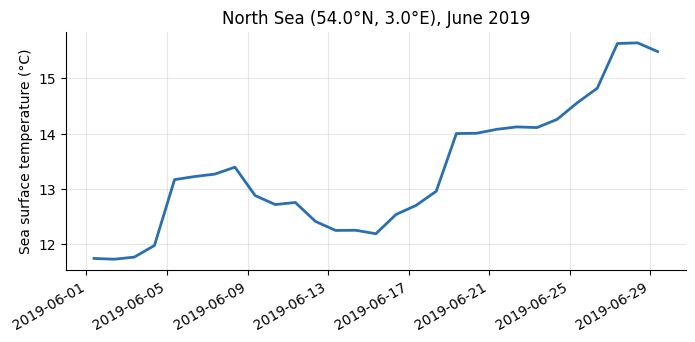

In [8]:
times = series["time"].to_numpy()
celsius = series[VARIABLE].to_numpy() - KELVIN

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(times, celsius, color="#2a6fb0", linewidth=2)
ax.set_ylabel("Sea surface temperature (°C)")
ax.set_title("North Sea (54.0°N, 3.0°E), June 2019")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.autofmt_xdate()
plt.show()

## A small box

Two `(start, stop)` pairs give a bounding box. The table is in long format, with one row per grid cell in C order (longitude changes fastest), so a reshape turns it back into a grid. Land cells are null and show as grey.

In [9]:
start = time.perf_counter()
box = zx.extract(
    STORE,
    VARIABLE,
    lat=(50, 52),
    lon=(-2, 2),
    time="2019-06-01",
    storage_options=OPTIONS,
)
elapsed = time.perf_counter() - start
print(f"{box.num_rows} rows in {elapsed:.1f} s")

80601 rows in 7.4 s


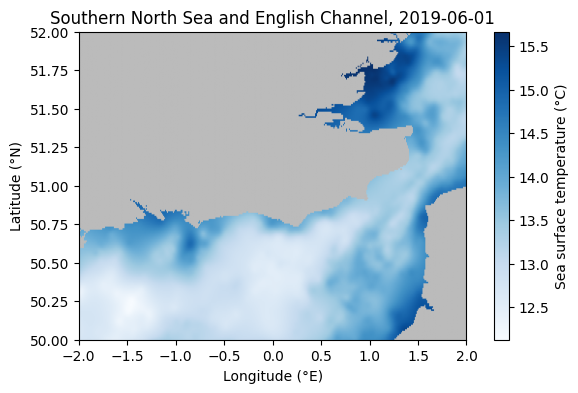

In [10]:
lat_all = box["lat"].to_numpy()
lon_all = box["lon"].to_numpy()
n_lat = np.unique(lat_all).size
n_lon = np.unique(lon_all).size

lat = lat_all.reshape(n_lat, n_lon)[:, 0]
lon = lon_all.reshape(n_lat, n_lon)[0]
grid = box[VARIABLE].to_numpy().reshape(n_lat, n_lon) - KELVIN
if lat[0] > lat[-1]:  # draw north at the top whatever the store's order
    lat, grid = lat[::-1], grid[::-1]

cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#bbbbbb")

fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(
    np.ma.masked_invalid(grid),
    origin="lower",
    extent=(lon[0], lon[-1], lat[0], lat[-1]),
    aspect=1 / np.cos(np.radians(51)),
    cmap=cmap,
)
fig.colorbar(image, ax=ax, label="Sea surface temperature (°C)")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Southern North Sea and English Channel, 2019-06-01")
plt.show()

## Parquet and SQL

The tables are Arrow tables, so writing Parquet is one call.

In [11]:
import pyarrow.parquet as pq

pq.write_table(series, "north_sea_june_2019.parquet")
print(pq.read_metadata("north_sea_june_2019.parquet"))

  created_by: parquet-cpp-arrow version 23.0.1
  num_columns: 4
  num_rows: 29
  num_row_groups: 1
  format_version: 2.6
  serialized_size: 921


If DuckDB is installed (Colab has it), it can query the file with SQL. Otherwise this cell does nothing.

In [12]:
try:
    import duckdb
except ImportError:
    print("duckdb is not installed, skipping")
else:
    result = duckdb.sql(
        """
        SELECT
            min(analysed_sst) - 273.15 AS min_celsius,
            max(analysed_sst) - 273.15 AS max_celsius,
            avg(analysed_sst) - 273.15 AS mean_celsius
        FROM 'north_sea_june_2019.parquet'
        """
    )
    print(result)

┌────────────────────┬────────────────────┬────────────────────┐
│    min_celsius     │    max_celsius     │    mean_celsius    │
│       double       │       double       │       double       │
├────────────────────┼────────────────────┼────────────────────┤
│ 11.733000000000004 │ 15.643000000000029 │ 13.335068965517166 │
└────────────────────┴────────────────────┴────────────────────┘

